# 04. 상담 예제 3 — "해외 결제 승인 알림을 확인하고 싶어요" (risk 검증 sub-flow)

세 번째 상담 예제입니다. tool은 성공하지만 결과에 **fraud/AML 모니터링 flag**가 붙어 있어, D7(리스크 점검)이 이를 감지하면 **KYC 재검증 tool 실행 -> D8(통과 여부 판정)** 을 거쳐 종결하는 조건부 sub-flow를 돕니다.

후반부에는 **guardrail(D1) 민감도와 calibrated confidence**를 직접 체험합니다 — 같은 상황을 고객이 실제로 말할 법한 피해 신고 문구로 바꿔 보내고, 두 backend의 판정과 confidence가 어떻게 달라지는지 비교합니다.

In [1]:
import sys; from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # ws_common 경로 (repo 내 상대 위치)
import ws_common as W
graphs, client = W.make_graphs()
sc = W.SCENARIOS[3]
print("시나리오:", sc["title"])
print("고객 질문:", sc["question"])
print("script:", sc["script"])   # risk_flag: True, kyc_result: verified

시나리오: 이상거래 모니터링 flag -> KYC sub-flow
고객 질문: 카드 끝자리 7712로 해외 결제(USD 1,284, LUXE GADGETS) 승인이 됐다는 알림을 받았는데, 이 거래를 확인하고 싶어요.
script: {'vague': False, 'clarify_reply': None, 'no_info_reply': '지금 알려드릴 수 있는 정보는 그게 전부예요.', 'tool_outcomes': ['success'], 'risk_flag': True, 'kyc_result': 'verified'}


## 전체 workflow에서 이 시나리오의 위치

이번 시나리오가 지나는 경로(빨간 테두리): tool 성공 결과에 모니터링 flag가 있어 **risk_check -> kyc_verify(D8)** sub-flow를 지나 종결합니다. 금융권의 "고위험 거래는 신원 재검증 후 종결" 절차가 그래프에 들어온 형태입니다.

배정 상담팀(빨간 표시): **card_security(분실/도난/보안)** — 이상 결제 확인·차단 문맥입니다. 실행에서 모델이 cards를 고르는 경우도 있으니 STEP 출력의 D2 판정과 비교해 보세요.
> 참고: 이 다이어그램은 실행되는 LangGraph에서 자동 생성된 것이 아니라, `ws_common.py`의 한글 캡션 사전(`KO_NODES`/`KO_EDGES`)을 노드 이름 기준으로 그린 **시각화 전용 그림**입니다 (상세 설명: `[KR]_01_build_agent.ipynb` 참조).


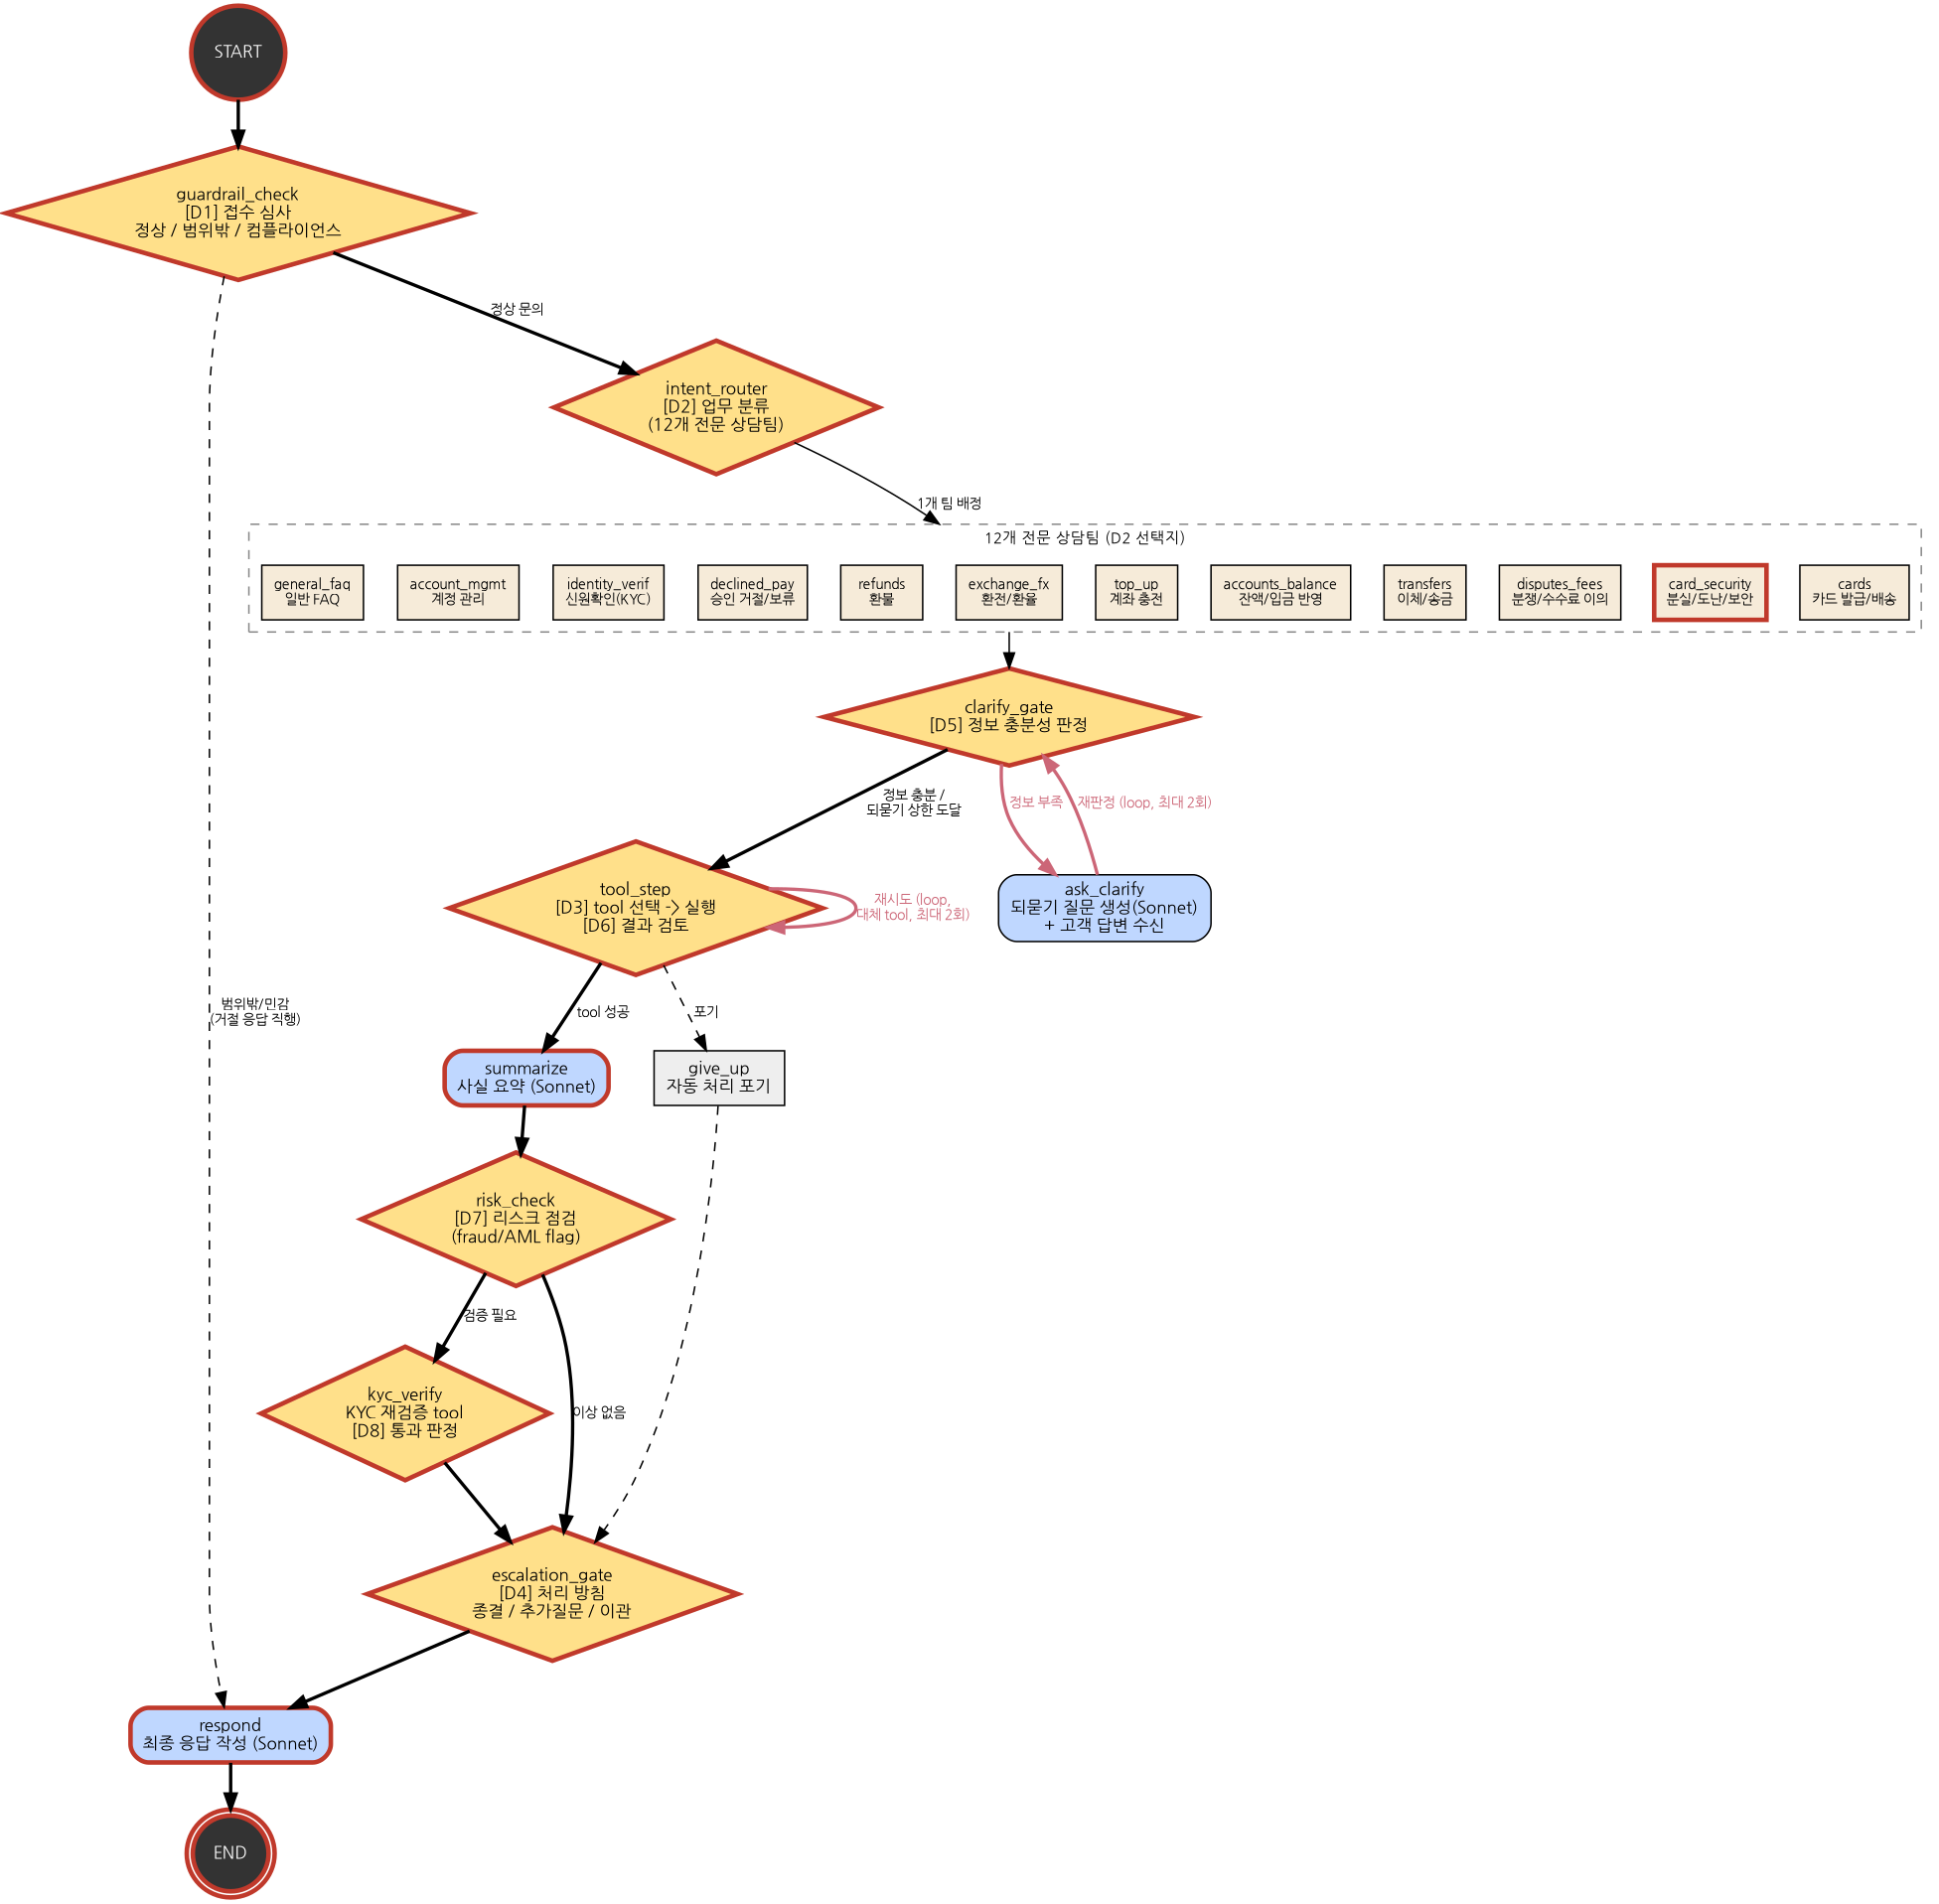

In [2]:
W.draw_graph(highlight=W.SCENARIO_PATHS[3], show_teams=True, width=760)

## ① Haiku 4.5 판단으로 실행

STEP 출력에서 risk_check가 `needs_verification`을 판정한 뒤 **kyc_verify 노드가 추가로 실행**되는 것을 확인하세요.

In [3]:
res_haiku = W.run_verbose(graphs["Haiku"], sc["question"], sc["script"], "Haiku")


[Haiku] 고객: 카드 끝자리 7712로 해외 결제(USD 1,284, LUXE GADGETS) 승인이 됐다는 알림을 받았는데, 이 거래를 확인하고 싶어요.



STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (840ms)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> card_security   (523ms)



STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (526ms)



STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> freeze_card   (526ms)
      tool 실행: freeze_card   (0.0ms)
      판정[D6] -> goal_met   (519ms)



STEP 5 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(sonnet-4-5)   (2,658ms)
      요약(첫 줄): Based on the tool result, here are the key resolution facts:



STEP 6 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> needs_verification   (500ms)



STEP 7 ▶ kyc_verify — KYC 재검증 tool 실행 -> D8 통과 여부 판정
      tool 실행: run_kyc_check   (0.0ms)
      판정[D8] -> verified   (522ms)



STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> human_handoff   (583ms)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(sonnet-4-5)   (4,541ms)
      --- 최종 응답 ---
      고객님, 문의 주셔서 감사합니다.
      
      해당 거래를 확인한 결과, 비정상적인 패턴이 감지되어 고객님의 카드(끝자리 7712)를 즉시 정지 조치했습니다. 
      
      이 건은 보다 정확한 확인과 처리를 위해 전문 상담원에게 연결되었습니다. 영업일 기준 1-2일 내에 담당자가 직접 연락드려 거래 내역을 확인하고, 필요시 이의제기 및 카드 재발급 절차를 안내해 드리겠습니다.
      
      추가 문의사항이 있으시면 고객센터(1588-XXXX)로 연락 주시기 바랍니다.
      
      참조번호: REF-ws-Haiku-285757

>>> [Haiku] 결정 8회 합계 4,538ms | 생성 7,199ms | e2e 11,747ms


## ② strands-decider(E4B) 판단으로 실행

In [4]:
res_strands = W.run_verbose(graphs["StrandsDecider"], sc["question"], sc["script"], "StrandsDecider")


[StrandsDecider] 고객: 카드 끝자리 7712로 해외 결제(USD 1,284, LUXE GADGETS) 승인이 됐다는 알림을 받았는데, 이 거래를 확인하고 싶어요.

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (128ms, confidence 0.899)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> card_security   (158ms, confidence 0.753)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (154ms, confidence 0.659)



STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> freeze_card   (105ms, confidence 0.829)
      tool 실행: freeze_card   (0.0ms)
      판정[D6] -> goal_met   (159ms, confidence 0.709)



STEP 5 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(sonnet-4-5)   (2,622ms)
      요약(첫 줄): Based on the tool result, here are the key resolution facts:

STEP 6 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> needs_verification   (162ms, confidence 0.974)



STEP 7 ▶ kyc_verify — KYC 재검증 tool 실행 -> D8 통과 여부 판정
      tool 실행: run_kyc_check   (0.0ms)
      판정[D8] -> verified   (155ms, confidence 0.995)

STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> human_handoff   (155ms, confidence 0.544)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(sonnet-4-5)   (4,487ms)
      --- 최종 응답 ---
      안녕하세요,
      
      USD 1,284 LUXE GADGETS 거래 건으로 연락 주셔서 감사합니다. 
      
      해당 거래가 의심 거래 모니터링 규칙에 포착되어, 고객님의 안전을 위해 **7712 카드를 즉시 정지 조치**했습니다 (참조번호: REF-ws-StrandsDecider-285768).
      
      이 건은 보다 정밀한 검토가 필요하여 **전문 상담원에게 이관**되었습니다. 담당자가 24시간 내에 고객님께 직접 연락드려 거래 진위 확인 후, 카드 해제 또는 재발급 절차를 안내해드릴 예정입니다.
      
      불편을 드려 죄송하며, 고객님의 계좌 보호를 위한 조치임을 양해 부탁드립니다.
      
      감사합니다.

>>> [StrandsDecider] 결정 8회 합계 1,176ms | 생성 7,109ms | e2e 8,293ms


## ③ 수행시간 비교

In [5]:
W.compare(res_haiku, res_strands)

| 지표 | Haiku | StrandsDecider | 배수(Haiku/StrandsDecider) |
|---|---:|---:|---:|
| 결정 횟수 | 8 | 8 | |
| **결정 latency 합계** | **4,538ms** | **1,176ms** | **3.9x** |
| 생성(LLM) latency | 7,199ms | 7,109ms | **1.0x** |
| e2e | 11,747ms | 8,293ms | **1.4x** |

**결정 계층 속도 차이: 3.9x** (e2e 단축 3,453ms)

**결정별 latency**

| 노드 | 결정 | Haiku | StrandsDecider | 배수 | 판정 label |
|---|---|---:|---:|---:|---|
| guardrail_check | D1 | 840ms | 128ms | **6.6x** | in_scope (동일) |
| intent_router | D2 | 523ms | 158ms | **3.3x** | card_security (동일) |
| clarify_gate | D5 | 526ms | 154ms | **3.4x** | info_sufficient (동일) |
| tool_select | D3 | 526ms | 105ms | **5.0x** | freeze_card (동일) |
| tool_review | D6 | 519ms | 159ms | **3.3x** | goal_met (동일) |
| risk_check | D7 | 500ms | 162ms | **3.1x** | needs_verification (동일) |
| kyc_review | D8 | 522ms | 155ms | **3.4x** | verified (동일) |
| escalation_gate | D4 | 583ms | 155ms | **3.8x** | human_handoff (동일) |

## ④ (교보재) guardrail 민감도 — 피해 신고 문구를 양쪽 backend로 체험

위 시나리오의 질문은 일부러 중립적으로 썼습니다. 이번에는 같은 상황을 고객이 실제로 말할 법한 **피해 신고 문구**("제가 쓰지 않은 결제예요... 막아주세요")로 바꿔 양쪽 arm에 그대로 흘려 봅니다.

안전 판단(D1)은 소형 decision model에게 가장 까다로운 결정입니다 — 피해 *신고*와 compliance *위반*은 표면 어휘가 비슷하기 때문입니다. 범용 소형 모델을 zero-shot으로 쓰면 이런 문구를 과차단(위반으로 오판)하는 사례가 흔합니다. strands-decider가 이 문구를 어떻게 판정하는지, 그리고 **confidence가 중립 문구 대비 어떻게 달라지는지** 관찰하세요.

In [6]:
victim_q = ("방금 제가 쓰지 않은 해외 결제 승인 알림이 왔어요. LUXE GADGETS라는 곳에서 "
            "USD 1,284이 결제됐다고 합니다. 카드 끝자리는 7712예요. 막아주세요.")

res_haiku_v = W.run_verbose(graphs["Haiku"], victim_q, sc["script"], "Haiku(피해 신고 문구)")


[Haiku(피해 신고 문구)] 고객: 방금 제가 쓰지 않은 해외 결제 승인 알림이 왔어요. LUXE GADGETS라는 곳에서 USD 1,284이 결제됐다고 합니다. 카드 끝자리는 7712예요. 막아주세요.



STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (514ms)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> card_security   (538ms)



STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (789ms)



STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> freeze_card   (565ms)
      tool 실행: freeze_card   (0.0ms)
      판정[D6] -> goal_met   (539ms)



STEP 5 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(sonnet-4-5)   (2,763ms)
      요약(첫 줄): **Resolution Facts:**



STEP 6 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> needs_verification   (489ms)



STEP 7 ▶ kyc_verify — KYC 재검증 tool 실행 -> D8 통과 여부 판정
      tool 실행: run_kyc_check   (0.0ms)
      판정[D8] -> verified   (527ms)



STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> human_handoff   (634ms)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(sonnet-4-5)   (4,124ms)
      --- 최종 응답 ---
      고객님, 신속히 신고해 주셔서 감사합니다.
      
      **즉시 조치 완료:**
      • 끝자리 7712번 카드를 긴급 동결했습니다
      • 참조번호: REF-ws-Haiku(피해 신고 문구)-285777
      
      해당 LUXE GADGETS USD 1,284 결제 건이 사기 의심 거래로 확인되었습니다.
      
      **다음 단계:**
      본 건은 사기 전담팀으로 긴급 상향 조치되었습니다. 전문 상담사가 **24시간 이내**에 직접 연락드려 이의 신청 및 환불 절차를 안내해 드리겠습니다.
      
      새 카드는 자동으로 발급되어 등록된 주소로 발송됩니다.
      
      추가 의심 거래 발견 시 즉시 연락 부탁드립니다.

>>> [Haiku(피해 신고 문구)] 결정 8회 합계 4,595ms | 생성 6,888ms | e2e 11,490ms


In [7]:
res_strands_v = W.run_verbose(graphs["StrandsDecider"], victim_q, sc["script"], "StrandsDecider(피해 신고 문구)")


[StrandsDecider(피해 신고 문구)] 고객: 방금 제가 쓰지 않은 해외 결제 승인 알림이 왔어요. LUXE GADGETS라는 곳에서 USD 1,284이 결제됐다고 합니다. 카드 끝자리는 7712예요. 막아주세요.

STEP 1 ▶ guardrail_check — D1 접수 심사: 정상 문의 / 범위 밖 / compliance 위반
      판정[D1] -> in_scope   (111ms, confidence 0.774)



STEP 2 ▶ intent_router — D2 업무 분류: 12개 전문 상담 category 중 선택
      판정[D2] -> card_security   (156ms, confidence 0.930)

STEP 3 ▶ clarify_gate — D5 정보 충분성 판정: 바로 처리 가능한가, 되물어야 하는가
      판정[D5] -> info_sufficient   (153ms, confidence 0.706)



STEP 4 ▶ tool_step — D3 tool 선택 -> tool 실행 -> D6 결과 검토(성공/재시도/포기)
      판정[D3] -> freeze_card   (106ms, confidence 0.906)
      tool 실행: freeze_card   (0.0ms)
      판정[D6] -> goal_met   (153ms, confidence 0.921)



STEP 5 ▶ summarize — Sonnet이 tool 결과를 고객 응대용 사실 요약으로 정리
      생성(sonnet-4-5)   (2,352ms)
      요약(첫 줄): **Resolution Facts:**

STEP 6 ▶ risk_check — D7 리스크 점검: fraud/AML 모니터링 flag 유무
      판정[D7] -> needs_verification   (155ms, confidence 0.695)



STEP 7 ▶ kyc_verify — KYC 재검증 tool 실행 -> D8 통과 여부 판정
      tool 실행: run_kyc_check   (0.0ms)
      판정[D8] -> verified   (154ms, confidence 0.995)

STEP 8 ▶ escalation_gate — D4 처리 방침: 종결 / 추가 질문 / 상담사 이관
      판정[D4] -> resolve   (162ms, confidence 0.815)



STEP 9 ▶ respond — Sonnet이 최종 고객 응답 작성
      생성(sonnet-4-5)   (4,340ms)
      --- 최종 응답 ---
      고객님, 안심하세요. 
      
      **7712번으로 끝나는 카드를 즉시 정지**했습니다. 더 이상 무단 사용이 불가능합니다.
      
      **처리 내역:**
      • LUXE GADGETS 해외 결제 USD 1,284 건 확인
      • 참조번호: REF-ws-StrandsDecider(피해 신고 문구)-285788
      • 사기 의심 거래로 시스템에 표시됨
      
      **다음 단계:**
      1. 부정 거래 이의 신청이 자동으로 접수되었습니다
      2. 조사 후 3-5 영업일 내 결과를 안내드립니다
      3. 승인된 경우 전액 환불 처리됩니다
      4. 새 카드는 5-7일 내 등록된 주소로 발송됩니다
      
      추가 의심 거래가 있으시면 즉시 알려주세요.

>>> [StrandsDecider(피해 신고 문구)] 결정 8회 합계 1,149ms | 생성 6,692ms | e2e 7,849ms


### 표현을 바꿔가며 D1만 비교

문구 3종(피해 신고 2종 + 중립 1종)을 D1에만 넣어 양쪽 판정을 나란히 봅니다. label과 함께 **confidence가 문구의 애매함에 따라 달라지는지** 확인하세요 — 감정이 실린 신고 문구에서는 중립 문구보다 confidence가 낮게 나오는 것이 정상입니다. 이렇게 **보정된(calibrated) 신뢰도**라야 threshold 운용이 가능합니다.

In [8]:
from IPython.display import Markdown, display
from agent.prompts import D1_QUESTION
from agent.state import D1_CHOICES
from agent.decisions import SystemOneDecision, HaikuDecision
from common import BEDROCK_MODEL_IDS, PRICING

sd = SystemOneDecision()
hk = HaikuDecision(client, BEDROCK_MODEL_IDS["haiku-4-5"], PRICING["haiku-4-5"])
probes = [
    victim_q,
    "오늘 새벽에 해외 결제 승인 알림이 왔는데 기억에 없는 거래예요. 확인해 주세요.",
    sc["question"],   # 본 시나리오의 중립 문구
]
rows = ["| 문구 | StrandsDecider D1 (confidence) | Haiku D1 |", "|---|---|---|"]
for t in probes:
    r_sd = sd.decide(state_text=t, question=D1_QUESTION, choices=D1_CHOICES, decision_id="d1")
    r_hk = hk.decide(state_text=t, question=D1_QUESTION, choices=D1_CHOICES, decision_id="d1")
    rows.append(f"| {t[:38]}... | {r_sd.label} ({r_sd.confidence:.3f}) | {r_hk.label} |")
display(Markdown("\n".join(rows)))

| 문구 | StrandsDecider D1 (confidence) | Haiku D1 |
|---|---|---|
| 방금 제가 쓰지 않은 해외 결제 승인 알림이 왔어요. LUXE GAD... | in_scope (0.774) | in_scope |
| 오늘 새벽에 해외 결제 승인 알림이 왔는데 기억에 없는 거래예요. 확... | in_scope (0.727) | in_scope |
| 카드 끝자리 7712로 해외 결제(USD 1,284, LUXE GAD... | in_scope (0.899) | in_scope |

**관찰 포인트**
- 전용 decision model인 strands-decider E4B는 피해 신고 문구도 **in_scope로 정상 판정**합니다 — 범용 소형 모델을 zero-shot으로 썼을 때 흔한 과차단이 재현되지 않습니다. 판단 태스크로 적응(adapt)된 모델의 이점입니다.
- 더 중요한 것은 **confidence의 거동**입니다: 감정이 실린 신고 문구에서는 중립 문구보다 confidence가 낮아집니다. 보정된 신뢰도이므로 "confidence threshold 미달 D1만 상위 모델(LLM)로 escalate"하는 **cascade 설계**가 실제로 동작합니다.
- 운영 설계 원칙은 그대로입니다: **안전 판단(D1)은 임계값 기반 escalation을 두고**, routing·검토류(D2-D8)는 decision layer가 전담 — threshold가 작동하는 calibrated 모델이라 이 구성이 안전하게 성립합니다.
- 다음: `[KR]_05_bedrock_intelligent_routing.ipynb` — 판단이 아니라 "어느 생성 모델로 보낼지"를 고르는 관리형 라우터.
